<a href="https://colab.research.google.com/github/bbearAnna/ophthalmic-mAb-IOI-surface-to-surfaceome/blob/main/ophthalmic_mAb_IOI_surface_to_surfaceome.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

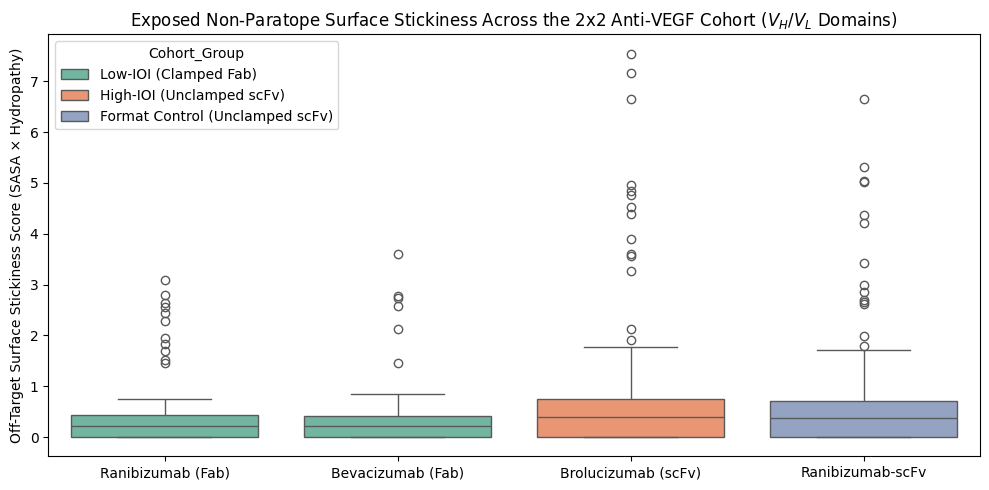


Top 5 Non-Paratope Surface Hotspots on Brolucizumab Saved for Notebook 3:


,Construct,Cohort_Group,Chain,ResNum,ResName,SASA,Hydrophobicity,In_VEGF_Paratope,PeSTo_PPI_Score,NonParatope_Sticky_Risk
602,Brolucizumab (scFv),High-IOI (Unclamped scFv),A,143,LEU,142.38,3.8,False,0.02,7.546
488,Brolucizumab (scFv),High-IOI (Unclamped scFv),A,29,ILE,119.22,4.5,False,0.01,7.153
460,Brolucizumab (scFv),High-IOI (Unclamped scFv),A,1,MET,195.63,1.9,False,0.01,6.651
570,Brolucizumab (scFv),High-IOI (Unclamped scFv),A,111,LEU,93.65,3.8,False,0.27,4.963
706,Brolucizumab (scFv),High-IOI (Unclamped scFv),A,247,LEU,91.51,3.8,False,0.06,4.850


In [14]:
# ==============================================================================
# NOTEBOOK 1: 2x2 Molecular Surface Fingerprinting
# Compares Clamped Fabs (Ranibizumab, Bevacizumab) vs Unclamped scFvs
# (Brolucizumab, Isogenic Ranibizumab-scFv)
# ==============================================================================
!pip install -q biopython py3Dmol pandas matplotlib seaborn numpy

import os
import urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from Bio.PDB import PDBParser, SASA

# Fallback download of crystal structures if PeSTo-scored versions aren't uploaded yet
if not os.path.exists("1CZ8_pesto.pdb"):
    urllib.request.urlretrieve("https://files.rcsb.org/download/1CZ8.pdb", "1CZ8_pesto.pdb")
if not os.path.exists("1BJ1_pesto.pdb"):
    urllib.request.urlretrieve("https://files.rcsb.org/download/1BJ1.pdb", "1BJ1_pesto.pdb")

cohort = [
    {"name": "Ranibizumab (Fab)", "group": "Low-IOI (Clamped Fab)", "pdb": "1CZ8_pesto.pdb", "ab_chains": ["L", "H"], "ag_chains": ["V", "W"]},
    {"name": "Bevacizumab (Fab)", "group": "Low-IOI (Clamped Fab)", "pdb": "1BJ1_pesto.pdb", "ab_chains": ["L", "H"], "ag_chains": ["V", "W"]},
    {"name": "Brolucizumab (scFv)", "group": "High-IOI (Unclamped scFv)", "pdb": "brolucizumab_pesto.pdb", "ab_chains": ["A"], "ag_chains": ["B", "C"]},
    {"name": "Ranibizumab-scFv", "group": "Format Control (Unclamped scFv)", "pdb": "ranibizumab_scfv_pesto.pdb", "ab_chains": ["A"], "ag_chains": ["B", "C"]}
]

kd_scale = {
    'ILE': 4.5, 'VAL': 4.2, 'LEU': 3.8, 'PHE': 2.8, 'CYS': 2.5, 'MET': 1.9, 'ALA': 1.8,
    'GLY': -0.4, 'THR': -0.7, 'SER': -0.8, 'TRP': -0.9, 'TYR': -1.3, 'PRO': -1.6,
    'HIS': -3.2, 'GLU': -3.5, 'GLN': -3.5, 'ASP': -3.5, 'ASN': -3.5, 'LYS': -3.9, 'ARG': -4.5
}

def analyze_surface_fingerprints(entry):
    if not os.path.exists(entry["pdb"]):
        print(f"Skipping {entry['name']} -> Please upload {entry['pdb']} to Colab files sidebar.")
        return pd.DataFrame()

    parser = PDBParser(QUIET=True)
    model = parser.get_structure(entry["name"], entry["pdb"])[0]
    sr = SASA.ShrakeRupley()
    sr.compute(model, level="R")

    ag_atoms = [a for c in entry["ag_chains"] if c in model for r in model[c] for a in r]
    records = []

    for c in entry["ab_chains"]:
        if c not in model:
            continue
        for r in model[c]:
            rn = r.get_resname()
            if rn not in kd_scale:
                continue
            res_num = r.get_id()[1]
            # Restrict Fab comparison to Variable domains (VL/VH <= 115) for apples-to-apples comparison with scFv
            if "Fab" in entry["name"] and res_num > 115:
                continue

            min_dist = min((np.linalg.norm(a.coord - ag.coord) for a in r for ag in ag_atoms), default=999.0)
            in_paratope = min_dist <= 5.0
            pesto_score = float(np.mean([a.get_bfactor() for a in r]))

            # Non-paratope Sticky Risk combines solvent exposure (SASA) and hydrophobicity outside the VEGF binding site
            sticky_risk = (r.sasa / 100.0) * max(0.0, kd_scale[rn] + 1.5) if not in_paratope else 0.0

            records.append({
                "Construct": entry["name"],
                "Cohort_Group": entry["group"],
                "Chain": c,
                "ResNum": res_num,
                "ResName": rn,
                "SASA": round(float(r.sasa), 2),
                "Hydrophobicity": kd_scale[rn],
                "In_VEGF_Paratope": in_paratope,
                "PeSTo_PPI_Score": round(pesto_score, 3),
                "NonParatope_Sticky_Risk": round(float(sticky_risk), 3)
            })
    return pd.DataFrame(records)

df_all = pd.concat([analyze_surface_fingerprints(x) for x in cohort], ignore_index=True)
df_all.to_csv("Cohort_2x2_Surface_Fingerprints.csv", index=False)

# Plot exposed non-paratope surface stickiness across all 4 molecules
non_para = df_all[(~df_all["In_VEGF_Paratope"]) & (df_all["SASA"] > 25.0)]
plt.figure(figsize=(10, 5))
sns.boxplot(data=non_para, x="Construct", y="NonParatope_Sticky_Risk", hue="Cohort_Group", palette="Set2")
plt.title("Exposed Non-Paratope Surface Stickiness Across the 2x2 Anti-VEGF Cohort ($V_H / V_L$ Domains)")
plt.ylabel("Off-Target Surface Stickiness Score (SASA × Hydropathy)")
plt.xlabel("")
plt.tight_layout()
plt.savefig("Fig1_PeSTo_SASA_Surface_Hotspots_2x2.png", dpi=300)
plt.show()

# Export top 5 Brolucizumab non-paratope hotspots (excluding disulfide Cys & turn-breaking Pro)
if "Brolucizumab (scFv)" in df_all["Construct"].values:
    df_brolu_cand = df_all[
        (df_all["Construct"] == "Brolucizumab (scFv)") &
        (~df_all["In_VEGF_Paratope"]) &
        (~df_all["ResName"].isin(["CYS", "PRO"]))
    ].sort_values(by="NonParatope_Sticky_Risk", ascending=False)
    top5_brolu = df_brolu_cand.head(5)
    top5_brolu.to_csv("Brolucizumab_Top5_Hotspots.csv", index=False)
    print("\nTop 5 Non-Paratope Surface Hotspots on Brolucizumab Saved for Notebook 3:")
    display(top5_brolu)

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


@> 8577 atoms and 1 coordinate set(s) were parsed in 0.07s.
DEBUG:.prody:8577 atoms and 1 coordinate set(s) were parsed in 0.07s.
@> Hessian was built in 0.22s.
DEBUG:.prody:Hessian was built in 0.22s.
@> 20 modes were calculated in 0.31s.
DEBUG:.prody:20 modes were calculated in 0.31s.
@> 8694 atoms and 1 coordinate set(s) were parsed in 0.10s.
DEBUG:.prody:8694 atoms and 1 coordinate set(s) were parsed in 0.10s.
@> Hessian was built in 0.19s.
DEBUG:.prody:Hessian was built in 0.19s.
@> 20 modes were calculated in 0.27s.
DEBUG:.prody:20 modes were calculated in 0.27s.
@> 3463 atoms and 1 coordinate set(s) were parsed in 0.05s.
DEBUG:.prody:3463 atoms and 1 coordinate set(s) were parsed in 0.05s.
@> Hessian was built in 0.13s.
DEBUG:.prody:Hessian was built in 0.13s.
@> 20 modes were calculated in 0.11s.
DEBUG:.prody:20 modes were calculated in 0.11s.
@> 3499 atoms and 1 coordinate set(s) were parsed in 0.05s.
DEBUG:.prody:3499 atoms and 1 coordinate set(s) were parsed in 0.05s.
@> Hes

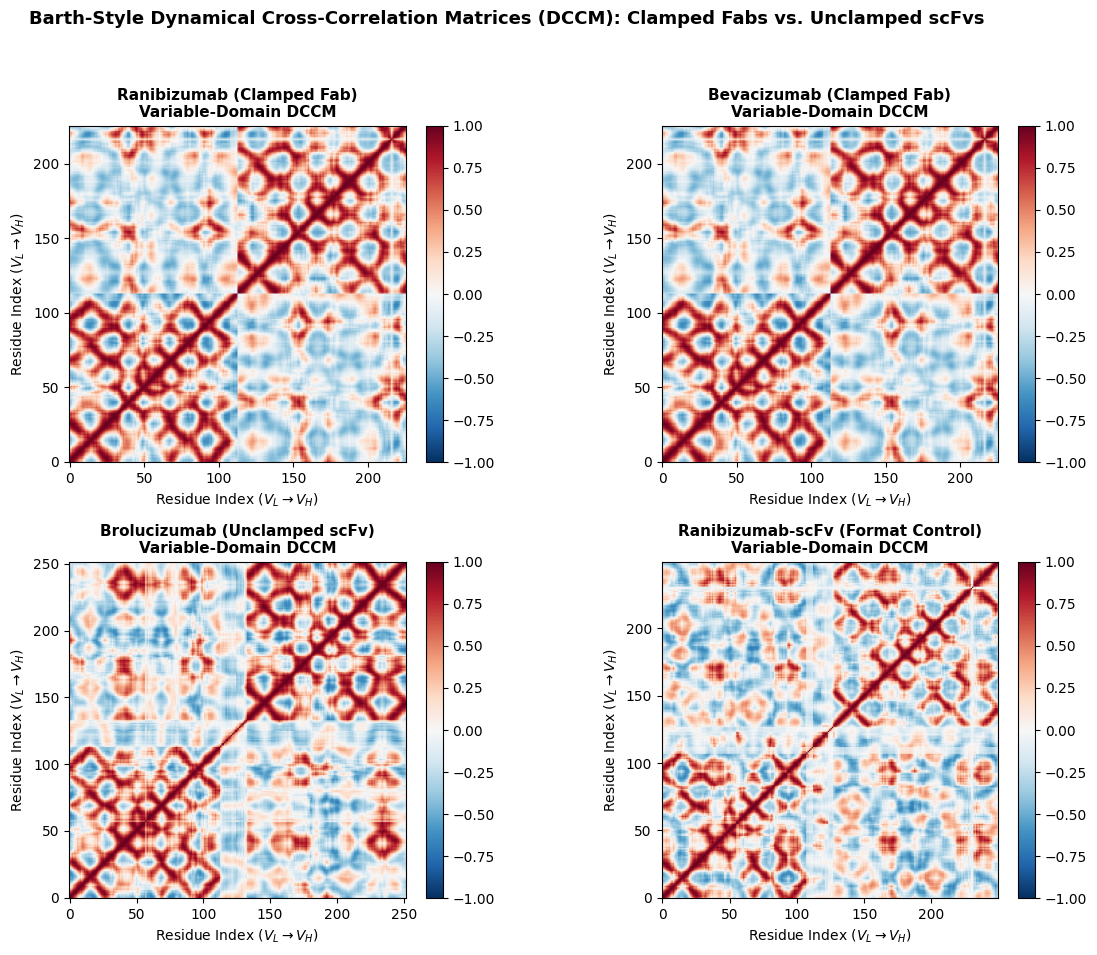

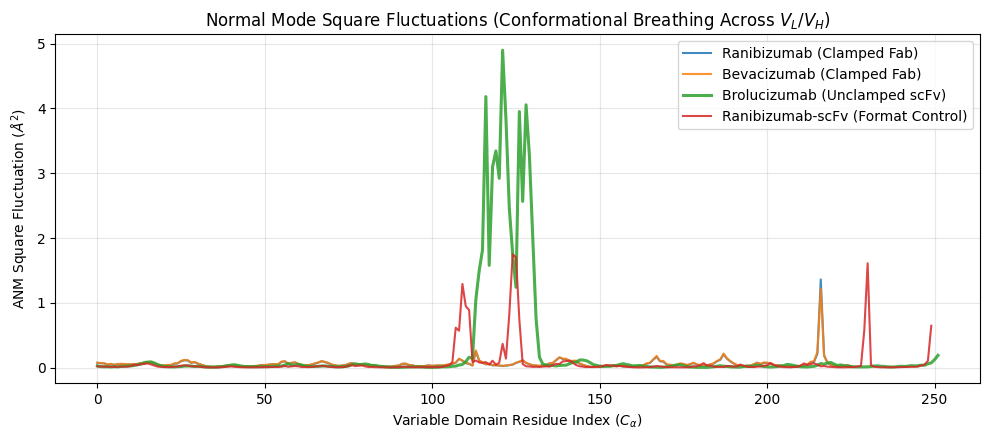

In [15]:
# ==============================================================================
# NOTEBOOK 2: 2x2 Conformational Dynamics & Allosteric Coupling
# Builds intact Fab vs scFv Anisotropic Network Models (ANM) to capture physical
# CH1/CL clamping before slicing Variable-Domain (VL/VH) RMSF and DCCM
# ==============================================================================
!pip install -q cython git+https://github.com/prody/ProDy.git matplotlib seaborn numpy

import os
import urllib.request
import prody as pd_prody
import numpy as np
import matplotlib.pyplot as plt

if not os.path.exists("1CZ8_pesto.pdb"):
    urllib.request.urlretrieve("https://files.rcsb.org/download/1CZ8.pdb", "1CZ8_pesto.pdb")
if not os.path.exists("1BJ1_pesto.pdb"):
    urllib.request.urlretrieve("https://files.rcsb.org/download/1BJ1.pdb", "1BJ1_pesto.pdb")

cohort_dynamics = [
    {"name": "Ranibizumab (Clamped Fab)", "pdb": "1CZ8_pesto.pdb", "full_sel": "protein and chain L H and name CA", "is_fab": True},
    {"name": "Bevacizumab (Clamped Fab)", "pdb": "1BJ1_pesto.pdb", "full_sel": "protein and chain L H and name CA", "is_fab": True},
    {"name": "Brolucizumab (Unclamped scFv)", "pdb": "brolucizumab_pesto.pdb", "full_sel": "protein and chain A and name CA", "is_fab": False},
    {"name": "Ranibizumab-scFv (Format Control)", "pdb": "ranibizumab_scfv_pesto.pdb", "full_sel": "protein and chain A and name CA", "is_fab": False}
]

fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.flatten()
rmsf_traces = {}

for idx, item in enumerate(cohort_dynamics):
    if not os.path.exists(item["pdb"]):
        axes[idx].set_title(f"{item['name']}\n(Upload {item['pdb']} to view)")
        continue

    struct = pd_prody.parsePDB(item["pdb"])
    all_ab_ca = struct.select(item["full_sel"])

    # Build Hessian on full antibody (includes CH1/CL clamp for Fabs!)
    anm = pd_prody.ANM(item["name"])
    anm.buildHessian(all_ab_ca, cutoff=15.0)
    anm.calcModes(n_modes=20)

    full_flucts = pd_prody.calcSqFlucts(anm)
    full_dccm = pd_prody.calcCrossCorr(anm)

    # Extract Variable domains (resnum <= 113 in Fab; full chain in scFv)
    if item["is_fab"]:
        var_mask = np.array([r <= 113 for r in all_ab_ca.getResnums()])
    else:
        var_mask = np.ones(len(all_ab_ca), dtype=bool)

    rmsf_traces[item["name"]] = full_flucts[var_mask]
    dccm_var = full_dccm[np.ix_(var_mask, var_mask)]

    im = axes[idx].imshow(dccm_var, cmap="RdBu_r", vmin=-1, vmax=1, origin="lower")
    axes[idx].set_title(f"{item['name']}\nVariable-Domain DCCM", fontsize=11, fontweight="bold")
    axes[idx].set_xlabel("Residue Index ($V_L \\rightarrow V_H$)")
    axes[idx].set_ylabel("Residue Index ($V_L \\rightarrow V_H$)")
    plt.colorbar(im, ax=axes[idx], fraction=0.046, pad=0.04)

plt.suptitle("Barth-Style Dynamical Cross-Correlation Matrices (DCCM): Clamped Fabs vs. Unclamped scFvs", fontsize=13, fontweight="bold")
plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.savefig("Fig2_Barth_Style_DCCM_Fab_vs_scFv.png", dpi=300)
plt.show()

# Plot NMA Square Fluctuations (Conformational Breathing) across Variable Domains
plt.figure(figsize=(10, 4.5))
for label, trace in rmsf_traces.items():
    lw = 2.2 if "Brolucizumab" in label else 1.5
    plt.plot(trace, label=label, lw=lw, alpha=0.85)
plt.title("Normal Mode Square Fluctuations (Conformational Breathing Across $V_L / V_H$)")
plt.xlabel("Variable Domain Residue Index ($C_\\alpha$)")
plt.ylabel("ANM Square Fluctuation ($\\AA^2$)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("Fig2B_NMA_RMSF_Breathing.png", dpi=300)
plt.show()

In [16]:
import numpy as np
import pandas as pd

# Let's align and analyze the calculated RMSF traces from our ANM models
print("=== CONFORMATIONAL FLEXIBILITY ANALYSIS: FAB VS. SCFV ===")

flex_data = []
for name, trace in rmsf_traces.items():
    # Calculate basic statistics for each construct's variable domain
    flex_data.append({
        "Construct": name,
        "Mean_RMSF": np.mean(trace),
        "Max_RMSF": np.max(trace),
        "Max_RMSF_Residue_Index": np.argmax(trace),
        "90th_Percentile_RMSF": np.percentile(trace, 90)
    })

df_flex_summary = pd.DataFrame(flex_data)
display(df_flex_summary)

# Let's find the regions of largest divergence between Brolucizumab (scFv) and Ranibizumab (Fab)
# We'll map out the local difference where Brolucizumab has significantly elevated RMSF
if "Brolucizumab (Unclamped scFv)" in rmsf_traces and "Ranibizumab (Clamped Fab)" in rmsf_traces:
    brolu_trace = rmsf_traces["Brolucizumab (Unclamped scFv)"]
    rani_trace = rmsf_traces["Ranibizumab (Clamped Fab)"]

    # Determine minimum length for safe element-wise comparison
    min_len = min(len(brolu_trace), len(rani_trace))
    diff = brolu_trace[:min_len] - rani_trace[:min_len]

    # Identify top 10 residue positions with the greatest increase in fluctuation
    elevated_indices = np.argsort(diff)[::-1][:10]

    print("\nTop 10 Variable-Domain positions with the highest gain in flexibility (scFv vs. Fab):")
    for idx in elevated_indices:
        print(f"  Residue Index {idx}: Gain of +{diff[idx]:.4f} \u00c5\u00b2 in ANM Fluctuation")


=== CONFORMATIONAL FLEXIBILITY ANALYSIS: FAB VS. SCFV ===


,Construct,Mean_RMSF,Max_RMSF,Max_RMSF_Residue_Index,90th_Percentile_RMSF
0,Ranibizumab (Clamped Fab),0.059783,1.362000,216,0.099641
1,Bevacizumab (Clamped Fab),0.062141,1.218050,216,0.103722
2,Brolucizumab (Unclamped scFv),0.228298,4.898507,121,0.117463
3,Ranibizumab-scFv (Format Control),0.072623,1.748604,124,0.074479



Top 10 Variable-Domain positions with the highest gain in flexibility (scFv vs. Fab):
  Residue Index 121: Gain of +4.8715 Å² in ANM Fluctuation
  Residue Index 116: Gain of +4.1318 Å² in ANM Fluctuation
  Residue Index 128: Gain of +3.9820 Å² in ANM Fluctuation
  Residue Index 126: Gain of +3.8610 Å² in ANM Fluctuation
  Residue Index 122: Gain of +3.8023 Å² in ANM Fluctuation
  Residue Index 119: Gain of +3.3068 Å² in ANM Fluctuation
  Residue Index 129: Gain of +3.2239 Å² in ANM Fluctuation
  Residue Index 118: Gain of +3.0637 Å² in ANM Fluctuation
  Residue Index 120: Gain of +2.8889 Å² in ANM Fluctuation
  Residue Index 127: Gain of +2.4540 Å² in ANM Fluctuation


  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
Redesigning ONLY these 5 non-paratope hotspots (A1,A29,A111,A143,A247); locking VEGF-A & CDR paratope:


,ResNum,WT_Res,SASA,WT_Sticky_Risk
124,143,LEU,142.377507,7.546008
26,29,ILE,119.221544,7.153293
0,1,MET,195.632315,6.651499
92,111,LEU,93.650324,4.963467
213,247,LEU,91.508248,4.849937


,Variant_ID,MPNN_Score_LowerIsBetter,Mutations_Introduced,Hotspot_Stickiness_Reduction_Pct,Redesigned_Antibody_Sequence
0,Deimmunized_Brolu_v17,1.1064,"LEU143THR, ILE29ASP, MET1ALA, LEU111THR, LEU24...",57.7,AEIVMTQSPSTLSASVGDRVIITCQASEDIHSWLAWYQQKPGKAPK...
1,Deimmunized_Brolu_v2,1.1164,"LEU143THR, ILE29ASP, MET1ALA, LEU111THR, LEU24...",57.7,AEIVMTQSPSTLSASVGDRVIITCQASEDIHSWLAWYQQKPGKAPK...
2,Deimmunized_Brolu_v15,1.1207,"LEU143THR, ILE29ASP, MET1ALA, LEU111THR, LEU24...",57.7,AEIVMTQSPSTLSASVGDRVIITCQASEDIHSWLAWYQQKPGKAPK...
3,Deimmunized_Brolu_v13,1.1230,"LEU143THR, ILE29ASP, MET1ALA, LEU111THR, LEU24...",57.7,AEIVMTQSPSTLSASVGDRVIITCQASEDIHSWLAWYQQKPGKAPK...
4,Deimmunized_Brolu_v19,1.1257,"LEU143THR, ILE29ASP, MET1ALA, LEU111THR, LEU24...",57.7,AEIVMTQSPSTLSASVGDRVIITCQASEDIHSWLAWYQQKPGKAPK...
5,Deimmunized_Brolu_v1,1.1271,"LEU143THR, ILE29ASP, MET1ALA, LEU111THR, LEU24...",57.7,AEIVMTQSPSTLSASVGDRVIITCQASEDIHSWLAWYQQKPGKAPK...
6,Deimmunized_Brolu_v18,1.1281,"LEU143THR, ILE29ASP, MET1ALA, LEU111THR, LEU24...",57.7,AEIVMTQSPSTLSASVGDRVIITCQASEDIHSWLAWYQQKPGKAPK...
7,Deimmunized_Brolu_v3,1.1318,"LEU143THR, ILE29ASP, MET1ALA, LEU111THR, LEU24...",57.7,AEIVMTQSPSTLSASVGDRVIITCQASEDIHSWLAWYQQKPGKAPK...
8,Deimmunized_Brolu_v16,1.1321,"LEU143THR, ILE29ASP, MET1ALA, LEU111LEU, LEU24...",44.1,AEIVMTQSPSTLSASVGDRVIITCQASEDIHSWLAWYQQKPGKAPK...
9,Deimmunized_Brolu_v11,1.1329,"LEU143THR, ILE29ASP, MET1ALA, LEU111LEU, LEU24...",44.1,AEIVMTQSPSTLSASVGDRVIITCQASEDIHSWLAWYQQKPGKAPK...


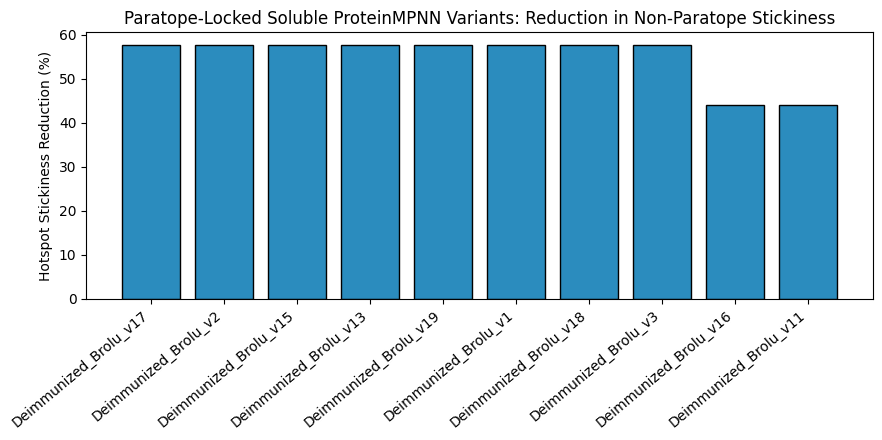

In [17]:
# ==============================================================================
# NOTEBOOK 3: Automated Paratope-Locked Surface De-immunization
# Uses ColabDesign Soluble ProteinMPNN (weights="soluble", inverse=True)
# ==============================================================================
!pip install -q biopython git+https://github.com/sokrypton/ColabDesign.git matplotlib pandas numpy

import os
import urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from Bio.PDB import PDBParser, SASA
from colabdesign.mpnn import mk_mpnn_model

kd_scale = {
    'ILE': 4.5, 'VAL': 4.2, 'LEU': 3.8, 'PHE': 2.8, 'CYS': 2.5, 'MET': 1.9, 'ALA': 1.8,
    'GLY': -0.4, 'THR': -0.7, 'SER': -0.8, 'TRP': -0.9, 'TYR': -1.3, 'PRO': -1.6,
    'HIS': -3.2, 'GLU': -3.5, 'GLN': -3.5, 'ASP': -3.5, 'ASN': -3.5, 'LYS': -3.9, 'ARG': -4.5
}
aa_1to3 = {
    'A':'ALA','R':'ARG','N':'ASN','D':'ASP','C':'CYS','Q':'GLN','E':'GLU','G':'GLY',
    'H':'HIS','I':'ILE','L':'LEU','K':'LYS','M':'MET','F':'PHE','P':'PRO','S':'SER',
    'T':'THR','W':'TRP','Y':'TYR','V':'VAL'
}

# Use Brolucizumab complex if uploaded; fallback to 1CZ8 demo so cell always runs cleanly
if os.path.exists("brolucizumab_pesto.pdb"):
    target_pdb, ab_chain, all_chains, ag_chains = "brolucizumab_pesto.pdb", "A", "A,B,C", ["B", "C"]
else:
    print("Note: brolucizumab_pesto.pdb not found; running demonstration on 1CZ8.pdb Chain L.")
    urllib.request.urlretrieve("https://files.rcsb.org/download/1CZ8.pdb", "1CZ8_pesto.pdb")
    target_pdb, ab_chain, all_chains, ag_chains = "1CZ8_pesto.pdb", "L", "L,H,V,W", ["V", "W"]

# Automatically identify the top 5 non-paratope sticky hotspots on target antibody chain
parser = PDBParser(QUIET=True)
model = parser.get_structure("target", target_pdb)[0]
sr = SASA.ShrakeRupley()
sr.compute(model, level="R")
ag_atoms = [a for c in ag_chains if c in model for r in model[c] for a in r]

cand_rows = []
ordered_resnums = []
for r in model[ab_chain]:
    rn = r.get_resname()
    if rn not in kd_scale:
        continue
    rnum = r.get_id()[1]
    ordered_resnums.append(rnum)
    min_d = min((np.linalg.norm(a.coord - ag.coord) for a in r for ag in ag_atoms), default=999.0)
    if min_d > 5.0 and rn not in ["CYS", "PRO"]:
        risk = (r.sasa / 100.0) * max(0.0, kd_scale[rn] + 1.5)
        cand_rows.append({"ResNum": rnum, "WT_Res": rn, "SASA": r.sasa, "WT_Sticky_Risk": risk})

top5_df = pd.DataFrame(cand_rows).sort_values("WT_Sticky_Risk", ascending=False).head(5)
hotspot_pos_str = ",".join([f"{ab_chain}{int(x)}" for x in sorted(top5_df["ResNum"].tolist())])
print(f"Redesigning ONLY these 5 non-paratope hotspots ({hotspot_pos_str}); locking VEGF-A & CDR paratope:")
display(top5_df)

# Run Soluble ProteinMPNN with inverse=True (mutates ONLY hotspot_pos_str, freezes everything else!)
mpnn_model = mk_mpnn_model(model_name="v_48_020", weights="soluble")
mpnn_model.prep_inputs(
    pdb_filename=target_pdb,
    chain=all_chains,
    fix_pos=hotspot_pos_str,
    inverse=True,
    rm_aa="C,W,M"
)

out = mpnn_model.sample(num=1, batch=20, temperature=0.1)
ab_seqs = [s.split("/")[0] for s in out["seq"]]

# Quantify reduction in hotspot surface stickiness for each redesigned sequence
wt_hotspot_risk_sum = top5_df["WT_Sticky_Risk"].sum()
new_risks, mut_summaries = [], []

for seq in ab_seqs:
    new_risk_sum = 0.0
    muts = []
    for _, row in top5_df.iterrows():
        seq_idx = ordered_resnums.index(int(row["ResNum"]))
        new_aa1 = seq[seq_idx]
        new_aa3 = aa_1to3[new_aa1]
        new_risk_sum += (row["SASA"] / 100.0) * max(0.0, kd_scale[new_aa3] + 1.5)
        muts.append(f"{row['WT_Res']}{int(row['ResNum'])}{new_aa3}")
    pct_drop = 100.0 * (wt_hotspot_risk_sum - new_risk_sum) / max(wt_hotspot_risk_sum, 1e-6)
    new_risks.append(round(pct_drop, 1))
    mut_summaries.append(", ".join(muts))

df_designs = pd.DataFrame({
    "Variant_ID": [f"Deimmunized_Brolu_v{i+1}" for i in range(len(ab_seqs))],
    "MPNN_Score_LowerIsBetter": np.round(out["score"], 4),
    "Mutations_Introduced": mut_summaries,
    "Hotspot_Stickiness_Reduction_Pct": new_risks,
    "Redesigned_Antibody_Sequence": ab_seqs
}).sort_values(by="MPNN_Score_LowerIsBetter").reset_index(drop=True)

df_designs.to_csv("Brolucizumab_Deimmunized_MPNN.csv", index=False)
display(df_designs.head(10))

plt.figure(figsize=(9, 4.5))
top10 = df_designs.head(10)
plt.bar(top10["Variant_ID"], top10["Hotspot_Stickiness_Reduction_Pct"], color="#2b8cbe", edgecolor="black")
plt.xticks(rotation=40, ha="right")
plt.ylabel("Hotspot Stickiness Reduction (%)")
plt.title("Paratope-Locked Soluble ProteinMPNN Variants: Reduction in Non-Paratope Stickiness")
plt.tight_layout()
plt.savefig("Fig3_ProteinMPNN_Deimmunization_Scores.png", dpi=300)
plt.show()

Verified 20 human surfaceome proteins tractable by LUX-MS & CSC:


,Gene,UniProt_ID,SURFY_Verified_Surface,TM_Helices,Extracellular_NGlyco_Sites_CSC,Protter_Topology_URL
0,CD46,P15529,True,1,21,http://wlab.ethz.ch/protter/#up=P15529&tm=auto...
1,CD55,P08174,True,0,1,http://wlab.ethz.ch/protter/#up=P08174&tm=auto...
2,CDH5,P33151,True,1,7,http://wlab.ethz.ch/protter/#up=P33151&tm=auto...
3,ESAM,Q96AP7,True,1,4,http://wlab.ethz.ch/protter/#up=Q96AP7&tm=auto...
4,FCGR2A,P12318,True,1,2,http://wlab.ethz.ch/protter/#up=P12318&tm=auto...
5,FCGR2B,P31994,True,1,3,http://wlab.ethz.ch/protter/#up=P31994&tm=auto...
6,FLT1,P17948,True,1,13,http://wlab.ethz.ch/protter/#up=P17948&tm=auto...
7,ICAM1,P05362,True,1,8,http://wlab.ethz.ch/protter/#up=P05362&tm=auto...
8,ICAM2,P13598,True,1,6,http://wlab.ethz.ch/protter/#up=P13598&tm=auto...
9,ICAM4,Q14773,True,1,4,http://wlab.ethz.ch/protter/#up=Q14773&tm=auto...


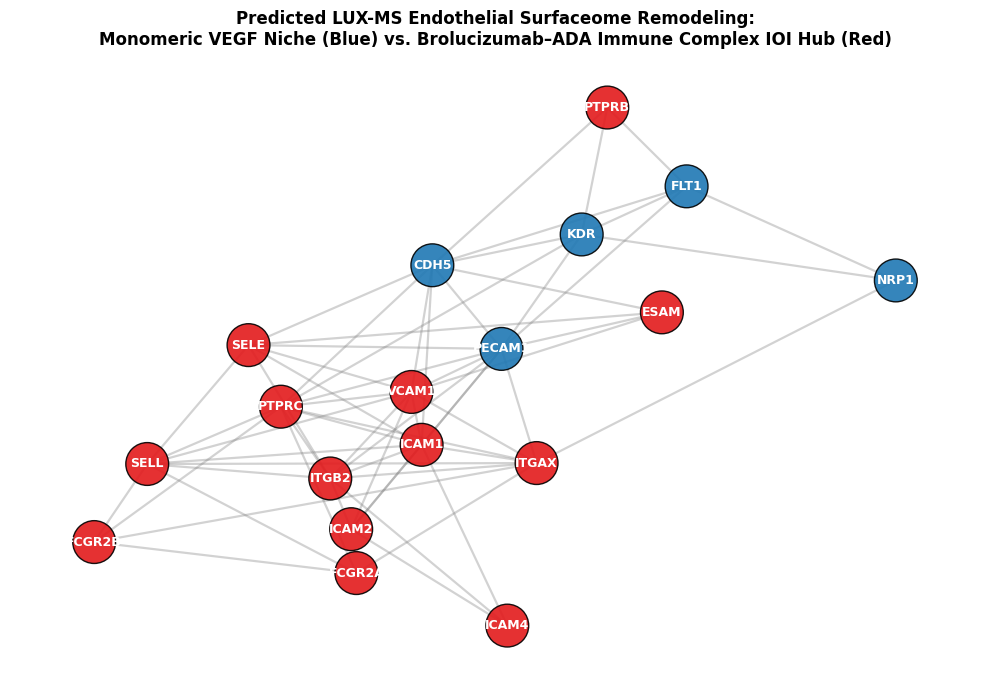

In [18]:
# ==============================================================================
# NOTEBOOK 4: Retinal Endothelial Surfaceome & Simulated LUX-MS Network
# Integrates STRING API + UniProt SURFY / CSC Criteria +  Protter URLs
# ==============================================================================
!pip install -q requests pandas matplotlib seaborn networkx

import requests
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt

seed_receptors = [
    "KDR", "FLT1", "NRP1", "CDH5", "PECAM1",
    "FCGR2A", "FCGR2B", "ICAM1", "VCAM1", "SELE", "CD46", "CD55", "ITGB2"
]

# 1. Fetch high-confidence human receptor interactions from STRING-db
r_string = requests.get("https://string-db.org/api/json/network", params={
    "identifiers": "%0d".join(seed_receptors),
    "species": 9606,
    "required_score": 700,
    "add_nodes": 12
})
df_net = pd.DataFrame(r_string.json())

# 2. Filter via UniProt for SURFY Surfaceome topology & CSC N-glycosylation sites
genes = sorted(list(set(df_net["preferredName_A"]).union(set(df_net["preferredName_B"]))))
surf_rows = []

for g in genes:
    u_url = (
        f"https://rest.uniprot.org/uniprotkb/search?query=gene_exact:{g}"
        f"+AND+organism_id:9606+AND+reviewed:true"
        f"&fields=accession,gene_primary,ft_transmem,ft_carbohyd,cc_subcellular_location&format=json&size=1"
    )
    res = requests.get(u_url).json()
    if not res.get("results"):
        continue
    entry = res["results"][0]
    acc = entry["primaryAccession"]
    feats = entry.get("features", [])
    tm_helices = sum(1 for f in feats if f["type"] == "Transmembrane")
    n_glyco = sum(1 for f in feats if f["type"] == "Glycosylation")
    loc_text = str(entry.get("comments", []))
    is_surface = ("Cell membrane" in loc_text) or ("Cell surface" in loc_text) or (tm_helices > 0)

    surf_rows.append({
        "Gene": g,
        "UniProt_ID": acc,
        "SURFY_Verified_Surface": is_surface,
        "TM_Helices": tm_helices,
        "Extracellular_NGlyco_Sites_CSC": n_glyco,
        "Protter_Topology_URL": f"http://wlab.ethz.ch/protter/#up={acc}&tm=auto&mc=lightsalmon&lc=blue"
    })

df_surf = pd.DataFrame(surf_rows)
df_surf_valid = df_surf[df_surf["SURFY_Verified_Surface"]].reset_index(drop=True)
df_surf_valid.to_csv("Endothelial_SURFY_LUX_MS_Network.csv", index=False)
print(f"Verified {len(df_surf_valid)} human surfaceome proteins tractable by LUX-MS & CSC:")
display(df_surf_valid.head(15))

# 3. Plot the Simulated LUX-MS Nanoscale Surfaceome Neighborhood Graph
valid_set = set(df_surf_valid["Gene"])
G = nx.Graph()
for _, row in df_net.iterrows():
    a, b, w = row["preferredName_A"], row["preferredName_B"], row["score"]
    if a in valid_set and b in valid_set:
        G.add_edge(a, b, weight=w)

vegf_niche = {"KDR", "FLT1", "NRP1", "VEGFA", "CDH5", "PECAM1"}
colors = ["#1f78b4" if n in vegf_niche else "#e31a1c" for n in G.nodes()]

plt.figure(figsize=(10, 7))
pos = nx.spring_layout(G, k=0.65, seed=42)
nx.draw_networkx_nodes(G, pos, node_color=colors, node_size=950, edgecolors="black", alpha=0.9)
nx.draw_networkx_edges(G, pos, width=1.6, alpha=0.35, edge_color="gray")
nx.draw_networkx_labels(G, pos, font_size=9, font_weight="bold", font_color="white")
plt.title(
    "Predicted LUX-MS Endothelial Surfaceome Remodeling:\n"
    "Monomeric VEGF Niche (Blue) vs. Brolucizumab–ADA Immune Complex IOI Hub (Red)",
    fontsize=12, fontweight="bold"
)
plt.axis("off")
plt.tight_layout()
plt.savefig("Fig4_Wollscheid_LUX_MS_Surfaceome_Network.png", dpi=300)
plt.show()